##Name: Neilson Christopher
##NIM: 2802461965

In [ ]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler, LabelEncoder, RobustScaler
from sklearn.impute import KNNImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('Bangladesh_Crime_Dataset_A.csv')
df.head()

,Unnamed: 0,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
0,0,7.0,29,wednesday,0,morning,dhaka,dhaka,6.1,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
1,1,1.0,2,wednesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
2,2,1.0,4,tuesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
3,3,3.0,9,friday,1,night,dhaka,dhaka,0.0,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
4,4,8.0,34,thursday,0,night,dhaka,dhaka,21.9,9,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6574 entries, 0 to 6573
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              6574 non-null   int64  
 1   incident_month          5917 non-null   float64
 2   incident_week           6574 non-null   int64  
 3   incident_weekday        6574 non-null   object 
 4   weekend                 6574 non-null   int64  
 5   part_of_the_day         6457 non-null   object 
 6   incident_district       6246 non-null   object 
 7   incident_division       6574 non-null   object 
 8   precip                  6574 non-null   float64
 9   visibility              6574 non-null   int64  
 10  heatindex               6574 non-null   int64  
 11  season                  6574 non-null   object 
 12  male_population         6574 non-null   int64  
 13  female_population       6574 non-null   int64  
 14  total_population        6574 non-null   

In [ ]:
df = df.drop(columns=['Unnamed: 0'])

In [ ]:
print(df.shape)
print(df.describe())

(6574, 25)
       incident_month  incident_week      weekend       precip   visibility  \
count     5917.000000    6574.000000  6574.000000  6574.000000  6574.000000   
mean         6.210749      25.193946     0.273806     6.187998     9.488287   
std          3.319075      14.517965     0.445944    11.989998     0.922742   
min          1.000000       1.000000     0.000000     0.000000     4.000000   
25%          3.000000      13.000000     0.000000     0.000000     9.000000   
50%          6.000000      25.000000     0.000000     0.800000    10.000000   
75%          9.000000      37.000000     1.000000     7.500000    10.000000   
max         12.000000      53.000000     1.000000   204.600000    10.000000   

         heatindex  male_population  female_population  total_population  \
count  6574.000000     6.574000e+03       6.574000e+03      6.574000e+03   
mean     31.597657     8.936342e+05       7.544586e+05      1.648104e+06   
std       5.502593     1.605205e+06       1.28418

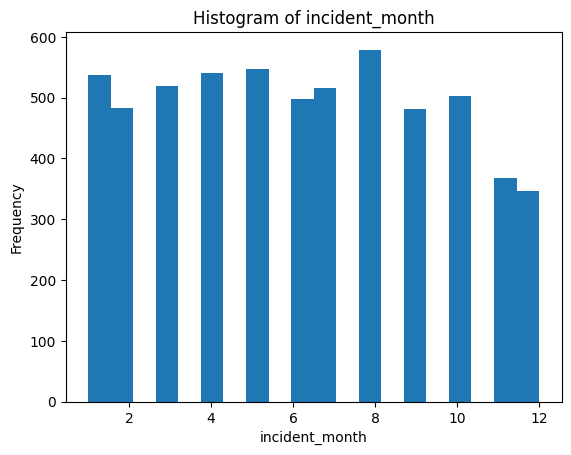

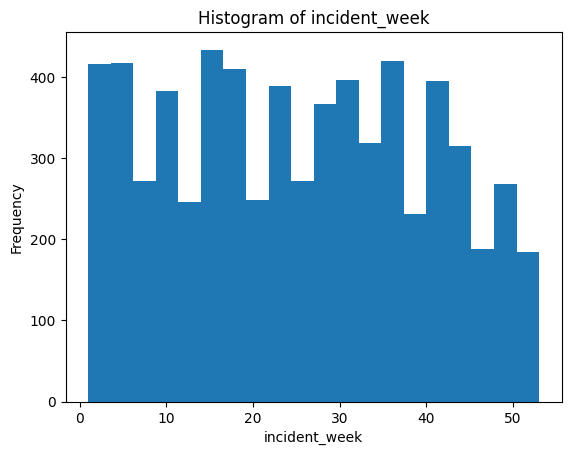

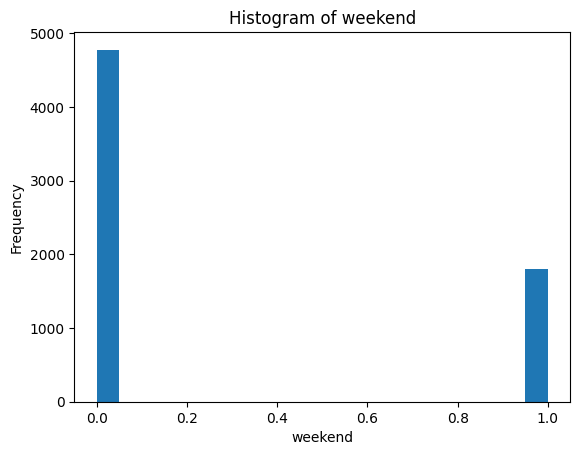

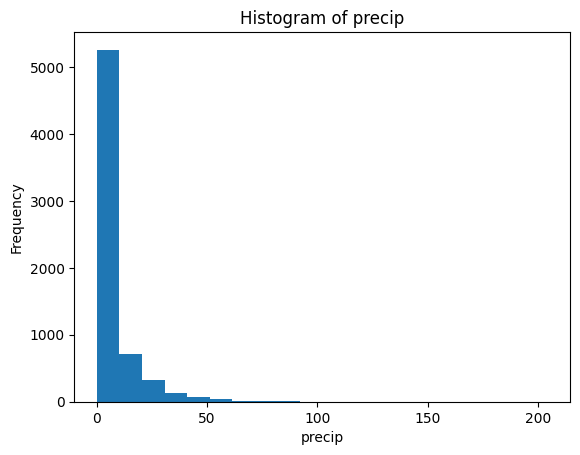

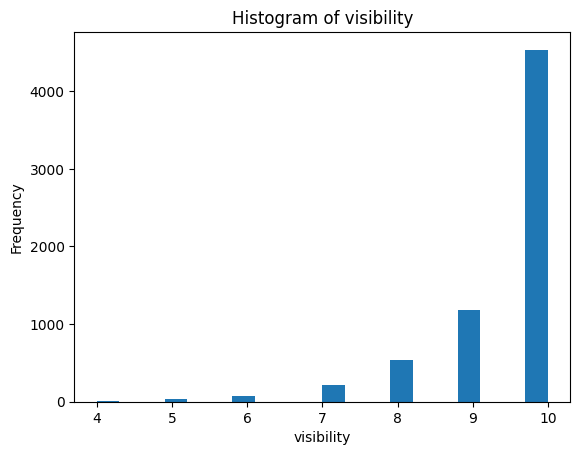

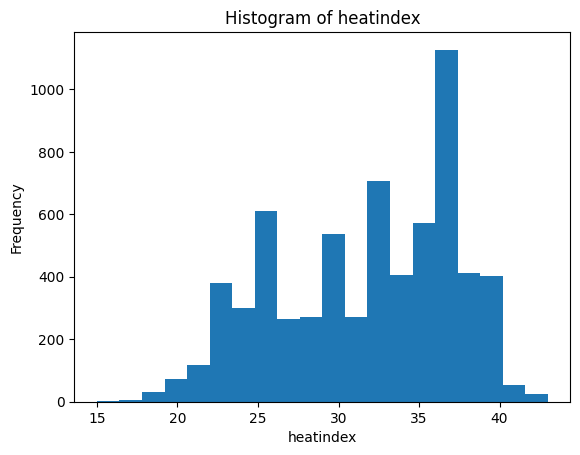

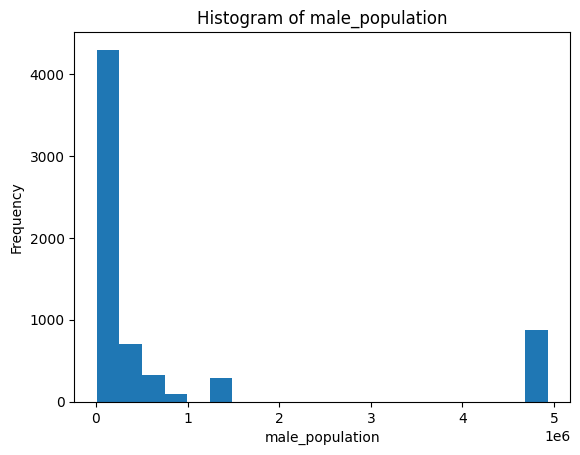

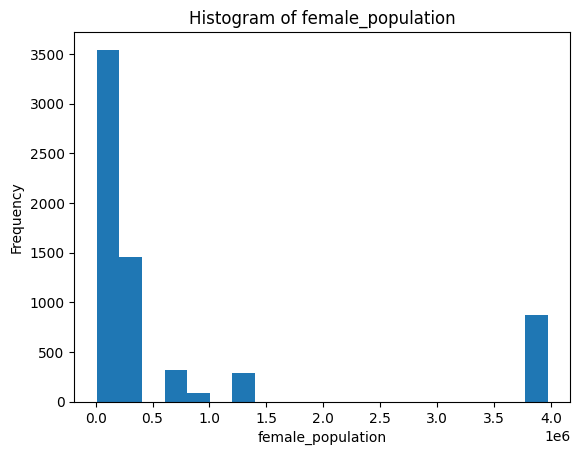

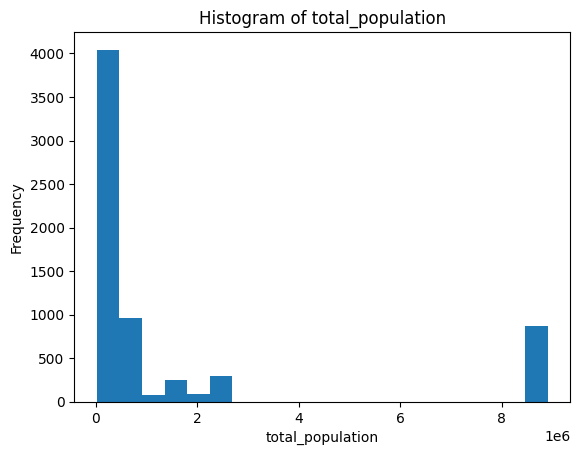

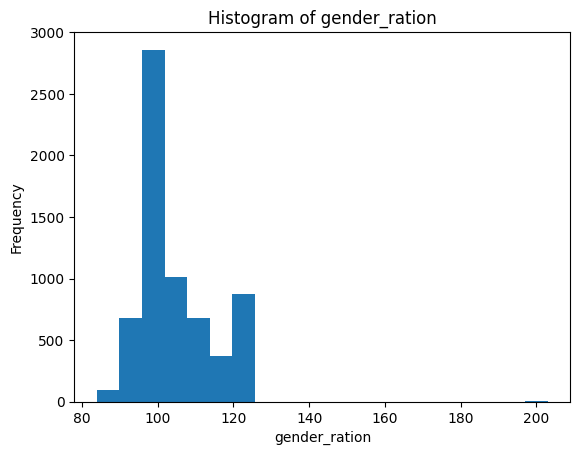

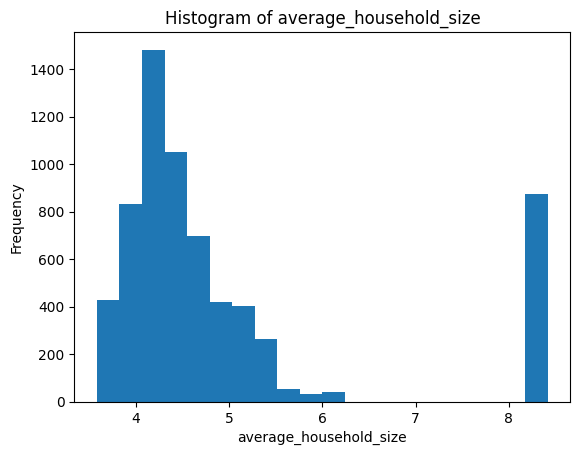

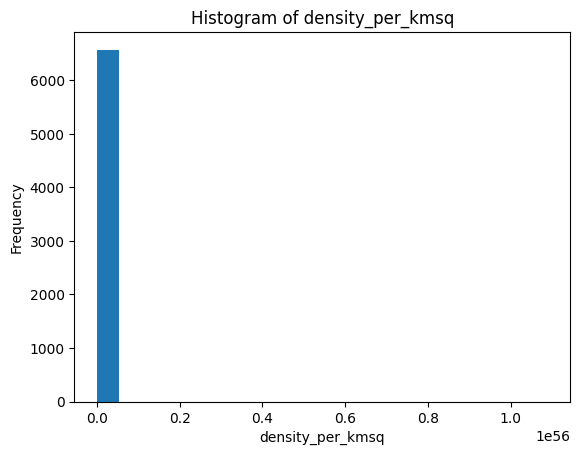

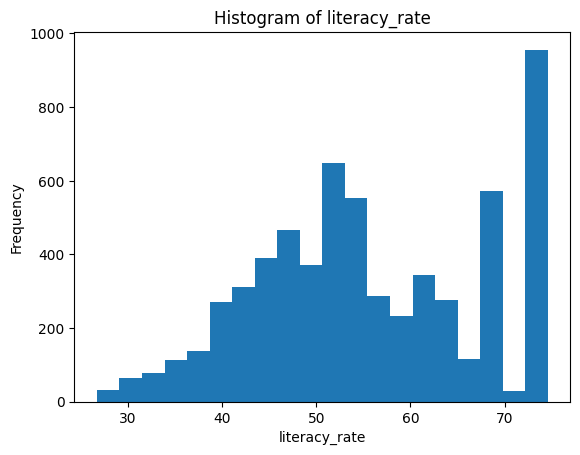

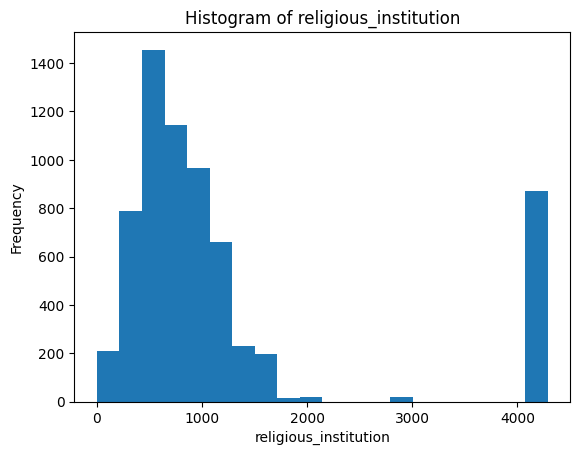

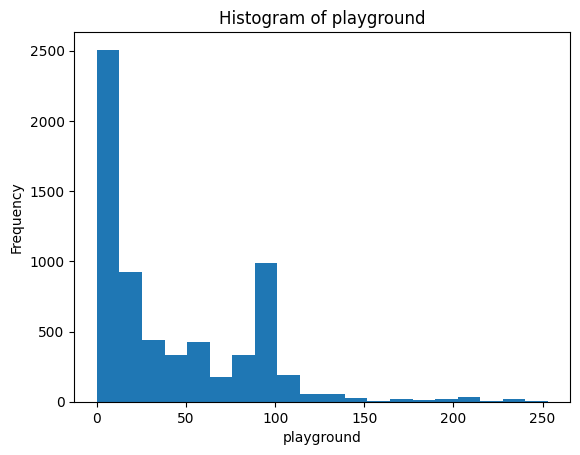

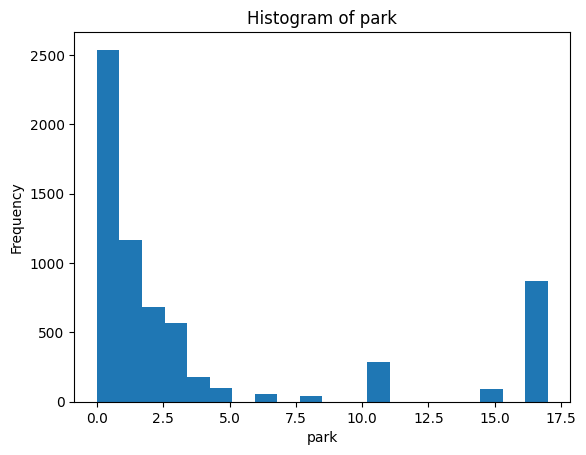

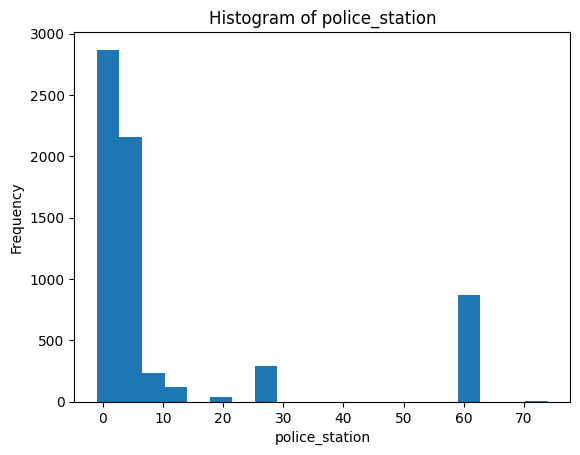

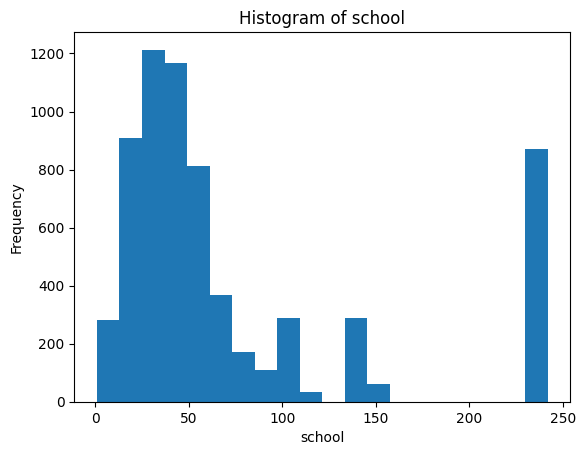

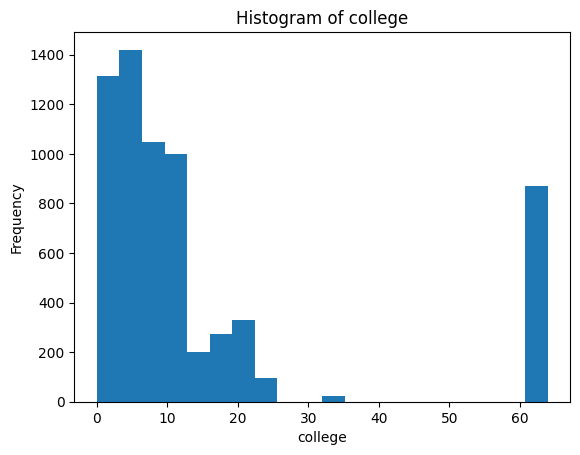

In [ ]:
num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    plt.figure()
    plt.hist(df[col], bins=20)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [ ]:
df.isna().sum()

,0
incident_month,657
incident_week,0
incident_weekday,0
weekend,0
part_of_the_day,117
incident_district,328
incident_division,0
precip,0
visibility,0
heatindex,0


In [ ]:
df['part_of_the_day'] = df['part_of_the_day'].fillna(df['part_of_the_day'].mode()[0])

In [ ]:
df["incident_district"] = (
    df.groupby("incident_division")["incident_district"]
      .transform(lambda x: x.fillna(x.mode().iloc[0]) if not x.mode().empty else x)
)


In [ ]:
df['incident_division'].value_counts()

,count
incident_division,
dhaka,1806
chattogram,918
rajshahi,700
rangpur,626
khulna,611
...,...
SYlheT,1
rAJsHAhI,1
SyLhet,1


In [ ]:
df['incident_division'] = df['incident_division'].str.lower()

In [ ]:
num = df.select_dtypes(include=["int64","float64"]).columns

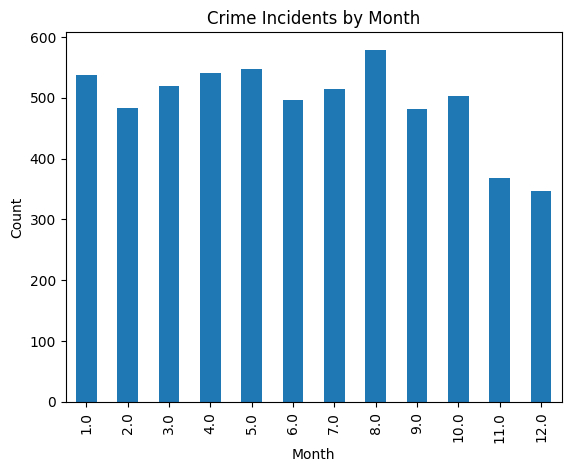

In [ ]:
plt.figure()
df["incident_month"].value_counts().sort_index().plot(kind="bar")
plt.title("Crime Incidents by Month")
plt.xlabel("Month")
plt.ylabel("Count")
plt.show()

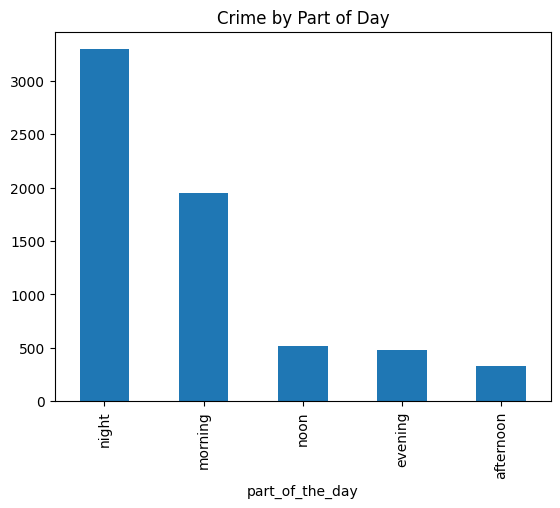

In [ ]:
plt.figure()
df["part_of_the_day"].value_counts().plot(kind="bar")
plt.title("Crime by Part of Day")
plt.show()


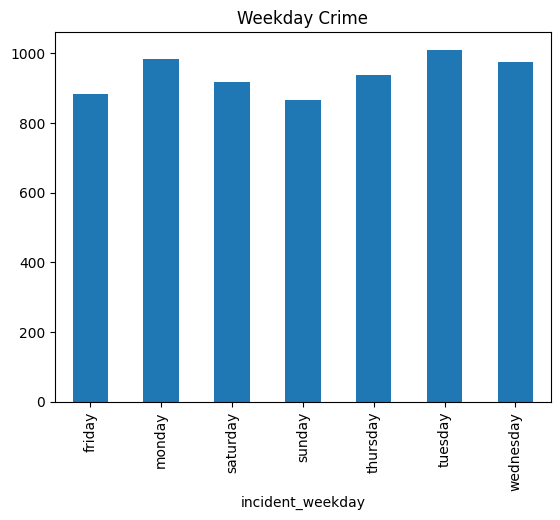

In [ ]:
plt.figure()
df.groupby("incident_weekday")["crime"].count().plot(kind="bar")
plt.title("Weekday Crime")
plt.show()

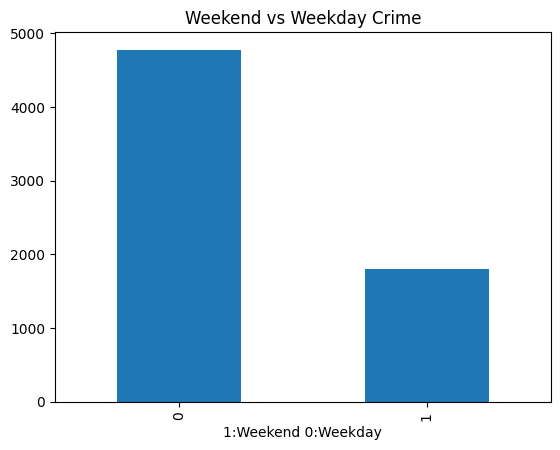

In [ ]:
plt.figure()
df.groupby("weekend")["crime"].count().plot(kind="bar")
plt.title("Weekend vs Weekday Crime")
plt.xlabel('1:Weekend 0:Weekday')
plt.show()

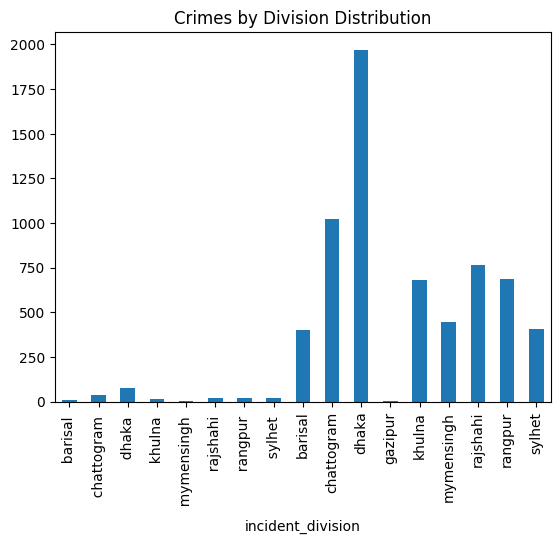

In [ ]:
plt.figure()
df.groupby("incident_division")["crime"].count().plot(kind="bar")
plt.title("Crimes by Division Distribution")
plt.show()

In [ ]:
handle = ['precip','visibility','heatindex','density_per_kmsq']

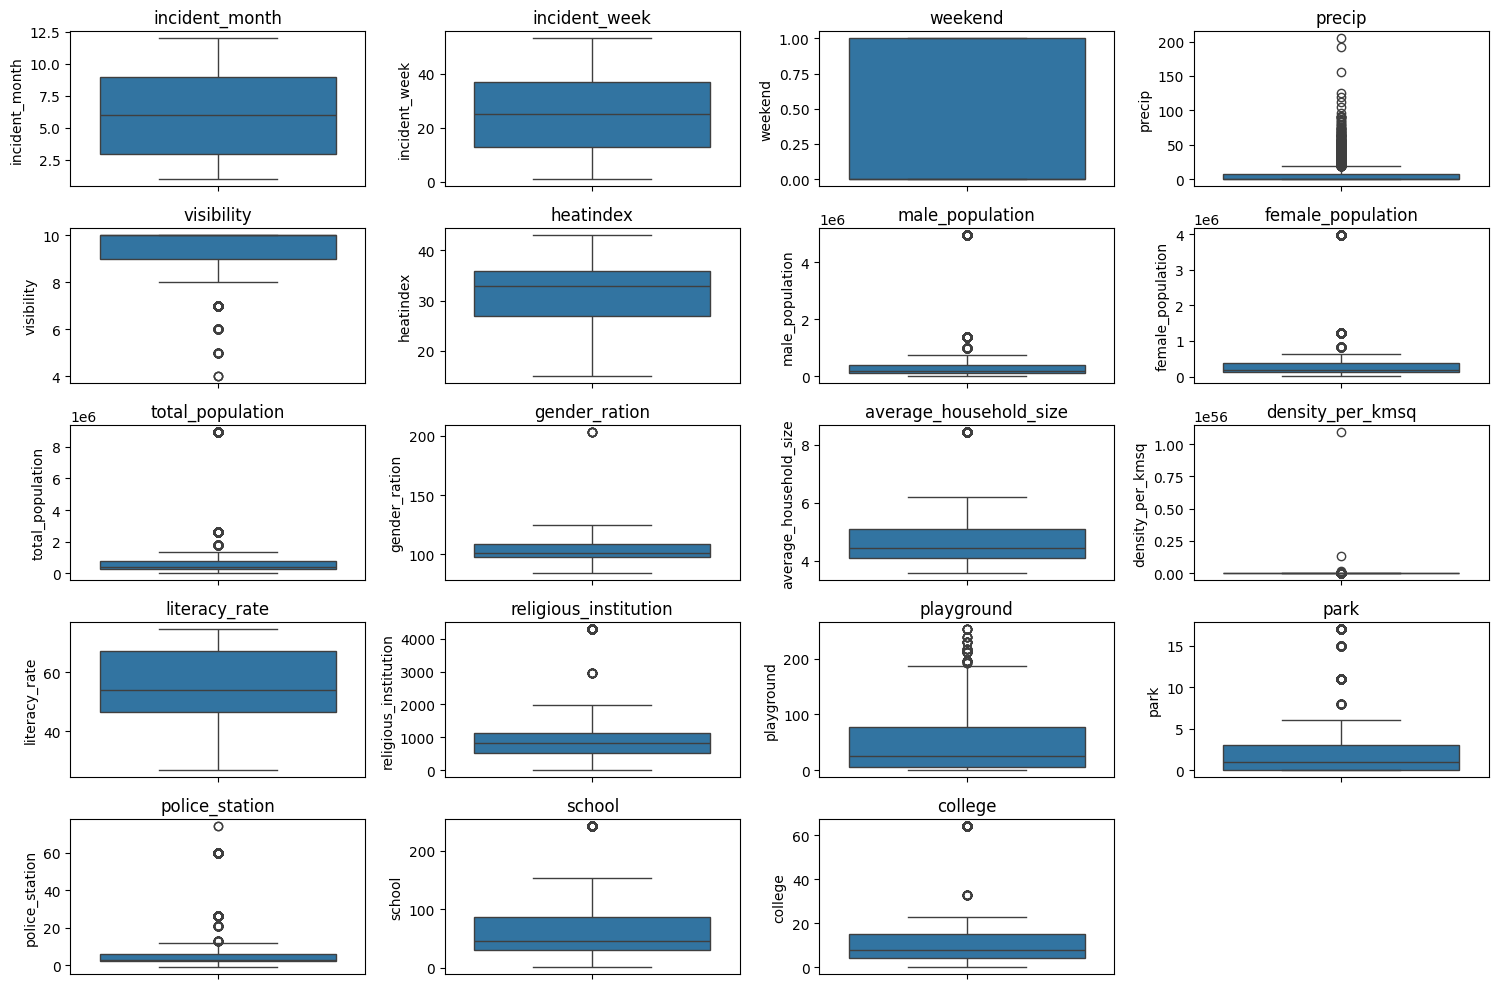


Outliers in incident_month: 0

Outliers in incident_week: 0

Outliers in weekend: 0

Outliers in precip: 686

Outliers in visibility: 319

Outliers in heatindex: 0

Outliers in male_population: 1250

Outliers in female_population: 1250

Outliers in total_population: 1250

Outliers in gender_ration: 7

Outliers in average_household_size: 872

Outliers in density_per_kmsq: 1307

Outliers in literacy_rate: 0

Outliers in religious_institution: 891

Outliers in playground: 87

Outliers in park: 1288

Outliers in police_station: 1225

Outliers in school: 872

Outliers in college: 895


In [ ]:
def detect_outliers(df):
    df_clean = df.copy()
    numerical_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns

    plt.figure(figsize=(15,10))
    for i, col in enumerate(numerical_cols, 1):
        plt.subplot(5, 4, i)
        sns.boxplot(data=df_clean, y=col)
        plt.title(f'{col}')
    plt.tight_layout()
    plt.show()

    for col in numerical_cols:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)][col]
        print(f"\nOutliers in {col}: {len(outliers)}")

detect_outliers(df)

In [ ]:
def handle_outliers(df, cols):
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
    return df

handle_outliers(df, handle)

,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,heatindex,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
0,7.0,29,wednesday,0,morning,dhaka,dhaka,6.10,10.0,32,...,8.42,9430.0,74.6,4289,99,17,60,242,64,murder
1,1.0,2,wednesday,0,night,dhaka,dhaka,0.00,10.0,22,...,8.42,9430.0,74.6,4289,99,17,60,242,64,murder
2,1.0,4,tuesday,0,night,dhaka,dhaka,0.00,10.0,25,...,8.42,9430.0,74.6,4289,99,17,60,242,64,murder
3,3.0,9,friday,1,night,dhaka,dhaka,0.00,10.0,30,...,8.42,9430.0,74.6,4289,99,17,60,242,64,murder
4,8.0,34,thursday,0,night,dhaka,dhaka,18.75,9.0,38,...,8.42,9430.0,74.6,4289,99,17,60,242,64,murder
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6569,3.0,10,tuesday,0,night,munshiganj,dhaka,8.50,9.0,27,...,4.55,1399.0,57.1,365,27,0,1,17,3,robbery
6570,10.0,42,saturday,1,night,munshiganj,dhaka,2.60,10.0,32,...,4.55,1399.0,57.1,365,27,0,1,17,3,robbery
6571,NaN,10,tuesday,0,night,munshiganj,dhaka,8.50,9.0,27,...,4.55,1399.0,57.1,365,27,0,1,17,3,robbery
6572,1.0,2,wednesday,0,night,sylhet,sylhet,0.00,10.0,17,...,5.82,893.0,49.4,359,1,0,1,19,3,robbery


In [ ]:
scaler = RobustScaler()
df_scaled = scaler.fit_transform(df[num])

In [ ]:
impute = KNNImputer(n_neighbors=5, weights='distance')
df_imputed = impute.fit_transform(df_scaled)

In [ ]:
df[num] = scaler.inverse_transform(df_imputed)

In [ ]:
features = [
    "precip", "visibility", "heatindex",
    "male_population", "female_population", "total_population",
    "density_per_kmsq", "literacy_rate",
    "religious_institution", "playground", "park",
    "police_station", "school", "college"
]

In [ ]:
x = df[features]

In [ ]:
scaler2 = RobustScaler()
x_final_scale= scaler2.fit_transform(x)

In [ ]:
inertia = []
silhouette = []

In [ ]:
k = range(2, 7)

for j in k:
  model = KMeans(n_clusters=j, random_state=3, n_init=10)
  labels = model.fit_predict(x_final_scale)
  inertia.append(model.inertia_)
  silhouette.append(silhouette_score(x_final_scale,labels))

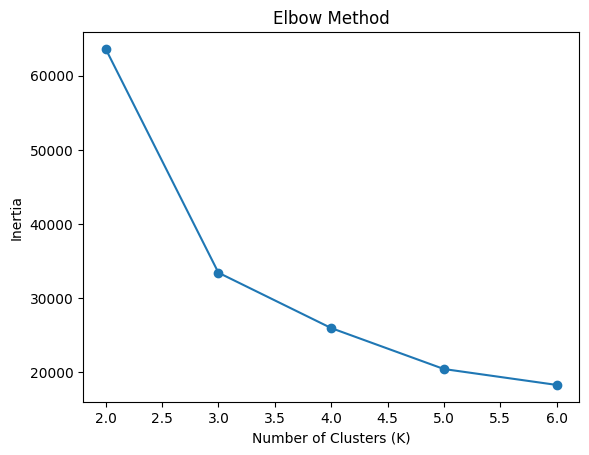

In [ ]:
plt.figure()
plt.plot(k, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


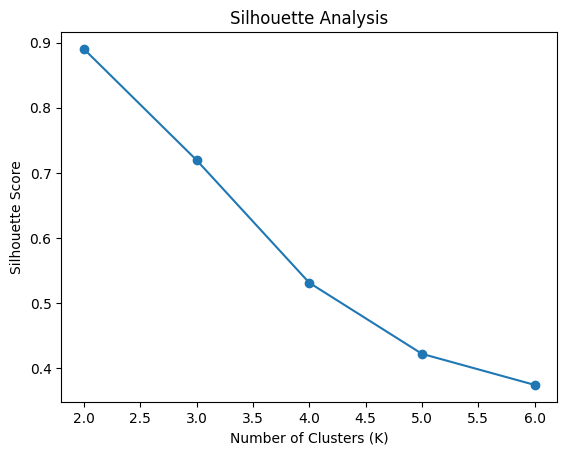

In [ ]:
plt.figure()
plt.plot(k, silhouette, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.show()


In [ ]:
print("Silhouette scores:", dict(zip(k, silhouette)))

Silhouette scores: {2: np.float64(0.8901756122438659), 3: np.float64(0.7195090194103415), 4: np.float64(0.5311514292138643), 5: np.float64(0.42200557252242354), 6: np.float64(0.3743157724256252)}


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=5, n_init=10)
df["cluster"] = kmeans.fit_predict(x_final_scale)

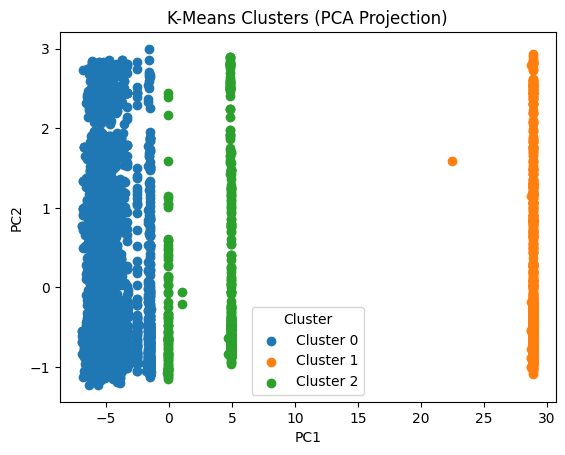

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(x_final_scale)

plt.figure()
for cluster in sorted(df["cluster"].unique()):
    plt.scatter(
        X_pca[df["cluster"] == cluster, 0],
        X_pca[df["cluster"] == cluster, 1],
        label=f"Cluster {cluster}"
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clusters (PCA Projection)")
plt.legend(title="Cluster")
plt.show()


In [ ]:
cluster_profile = df.groupby("cluster")[features].mean()
print(cluster_profile)

           precip  visibility  heatindex  male_population  female_population  \
cluster                                                                        
0        4.682901    9.529970  31.559376     2.051696e+05       2.001526e+05   
1        4.118635    9.590596  32.014908     4.931802e+06       3.974237e+06   
2        4.833289    9.473684  31.176316     1.269230e+06       1.129116e+06   

         total_population  density_per_kmsq  literacy_rate  \
cluster                                                      
0            4.053363e+05       1640.791502      51.868825   
1            8.906039e+06       9321.857798      74.600000   
2            2.398346e+06       8044.431579      66.753684   

         religious_institution  playground       park  police_station  \
cluster                                                                 
0                   750.753664   33.061255   1.138670        3.236565   
1                  4289.000000   99.000000  17.000000       59.930046

In [ ]:
crime_cluster = pd.crosstab(df["cluster"], df["crime"], normalize="index")
print(crime_cluster)

crime     assault  bodyfound    kidnap    murder      rape   robbery
cluster                                                             
0        0.162157   0.219091  0.103908  0.244833  0.192409  0.077602
1        0.180046   0.269495  0.076835  0.150229  0.141055  0.182339
2        0.202632   0.305263  0.081579  0.221053  0.121053  0.068421


In [ ]:
cluster_sizes = df["cluster"].value_counts()
print("Cluster sizes:\n", cluster_sizes)

Cluster sizes:
 cluster
0    5322
1     872
2     380
Name: count, dtype: int64
